In [1]:
import mne
import matplotlib.pyplot as plt

# Carrega as épocas no formato MNE
epochs = mne.read_epochs('epochs_vp001-epo.fif', preload=True)
print(epochs)

Reading /home/pedrobornia/Documents/topicos-especiais/epochs_vp001-epo.fif ...
    Found the data of interest:
        t =       0.00 ...    2225.00 ms
        0 CTF compensation matrices available
Not setting metadata
540 matching events found
No baseline correction applied
0 projection items activated
<EpochsFIF | 540 events (all good), 0 – 2.225 s (baseline off), ~55.2 MiB, data loaded,
 'non_target': 252
 'target': 288>


In [2]:
# Parâmetros para inspeção e seleção de 8 canais
classe_alvo = 'target'
indice_epoca = 1
canais_selecionados = ['AFz', 'Fp1', 'F1', 'F2', 'Cz', 'Pz', 'O1', 'O2']

In [3]:
def plots_evoked(evoked_data, canais=None, titulo="Único Evento - 8 Canais Selecionados", color="red"):
    data = evoked_data.get_data()[0]
    times = evoked_data.times
    ch_names = evoked_data.ch_names

    if canais is None:
        canais = ['AFz', 'Fp1', 'F1', 'F2', 'Cz', 'Pz', 'O1', 'O2']

    indices = [ch_names.index(ch) for ch in canais if ch in ch_names]
    canais_plot = [ch_names[i] for i in indices]

    fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(12, 10), sharex=True)
    axes = axes.flatten()

    for idx_plot, idx_canal in enumerate(indices):
        ax = axes[idx_plot]
        nome_canal = canais_plot[idx_plot]

        ax.plot(times, data[idx_canal], label=nome_canal, color=color, linewidth=1.0)
        ax.set_title(f"Canal: {nome_canal}")
        ax.grid(True, linestyle="--", alpha=0.5)

        if idx_plot % 2 == 0:
            ax.set_ylabel("Amplitude")

        if idx_plot >= 6:
            ax.set_xlabel("Tempo (s)")

    plt.suptitle(titulo, y=1.02, fontsize=14)
    plt.tight_layout()
    plt.show()

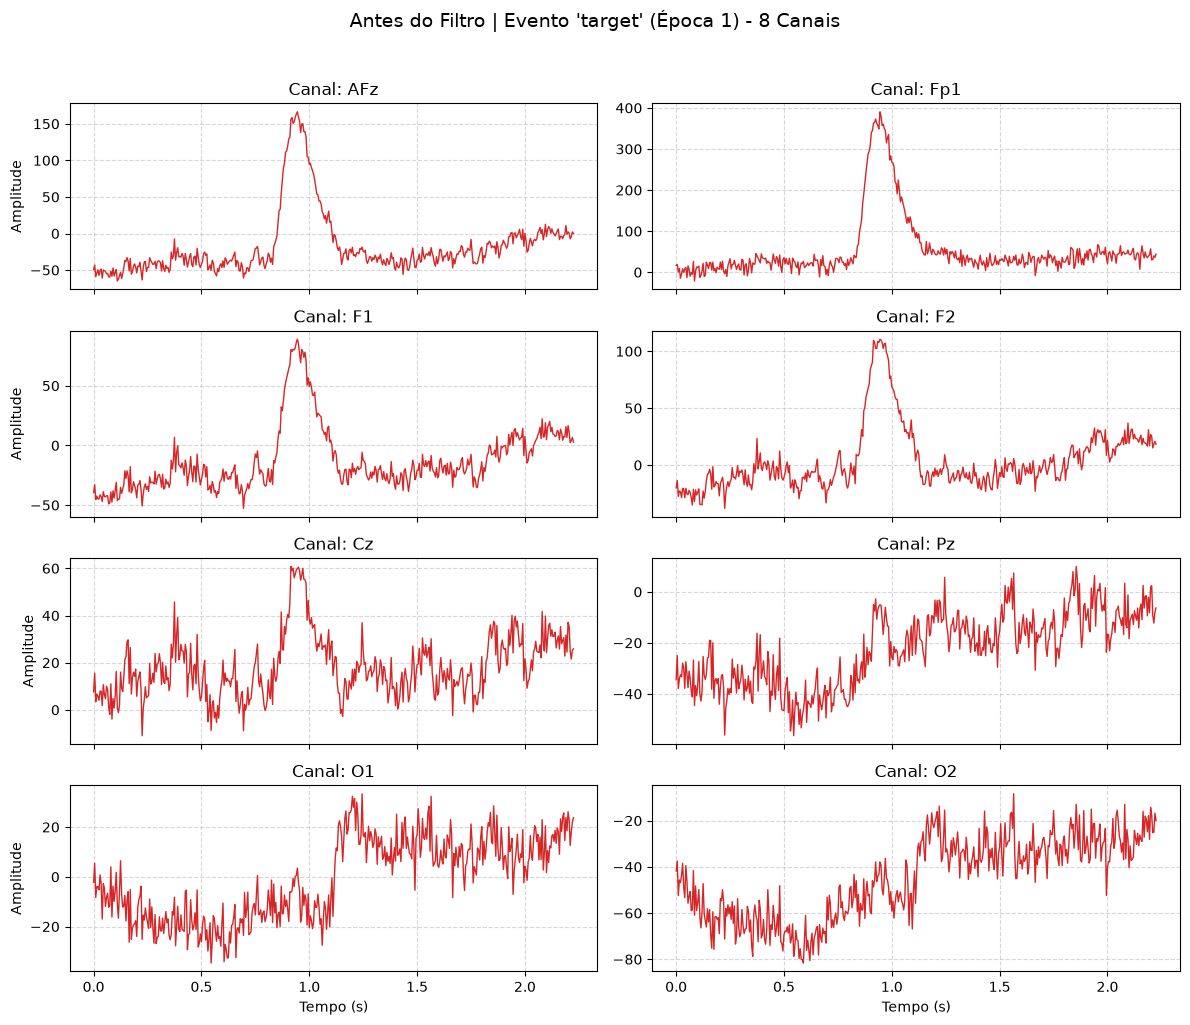

In [4]:
# Visualização da época isolada antes da filtragem
single_epoch = epochs[classe_alvo][indice_epoca]
plots_evoked(
    single_epoch,
    canais=canais_selecionados,
    titulo=f"Antes do Filtro | Evento '{classe_alvo}' (Época {indice_epoca}) - 8 Canais",
    color="#d62728"
)

Setting up band-pass filter from 1 - 30 Hz

IIR filter parameters
---------------------
Butterworth bandpass zero-phase (two-pass forward and reverse) non-causal filter:
- Filter order 16 (effective, after forward-backward)
- Cutoffs at 1.00, 30.00 Hz: -6.02, -6.02 dB



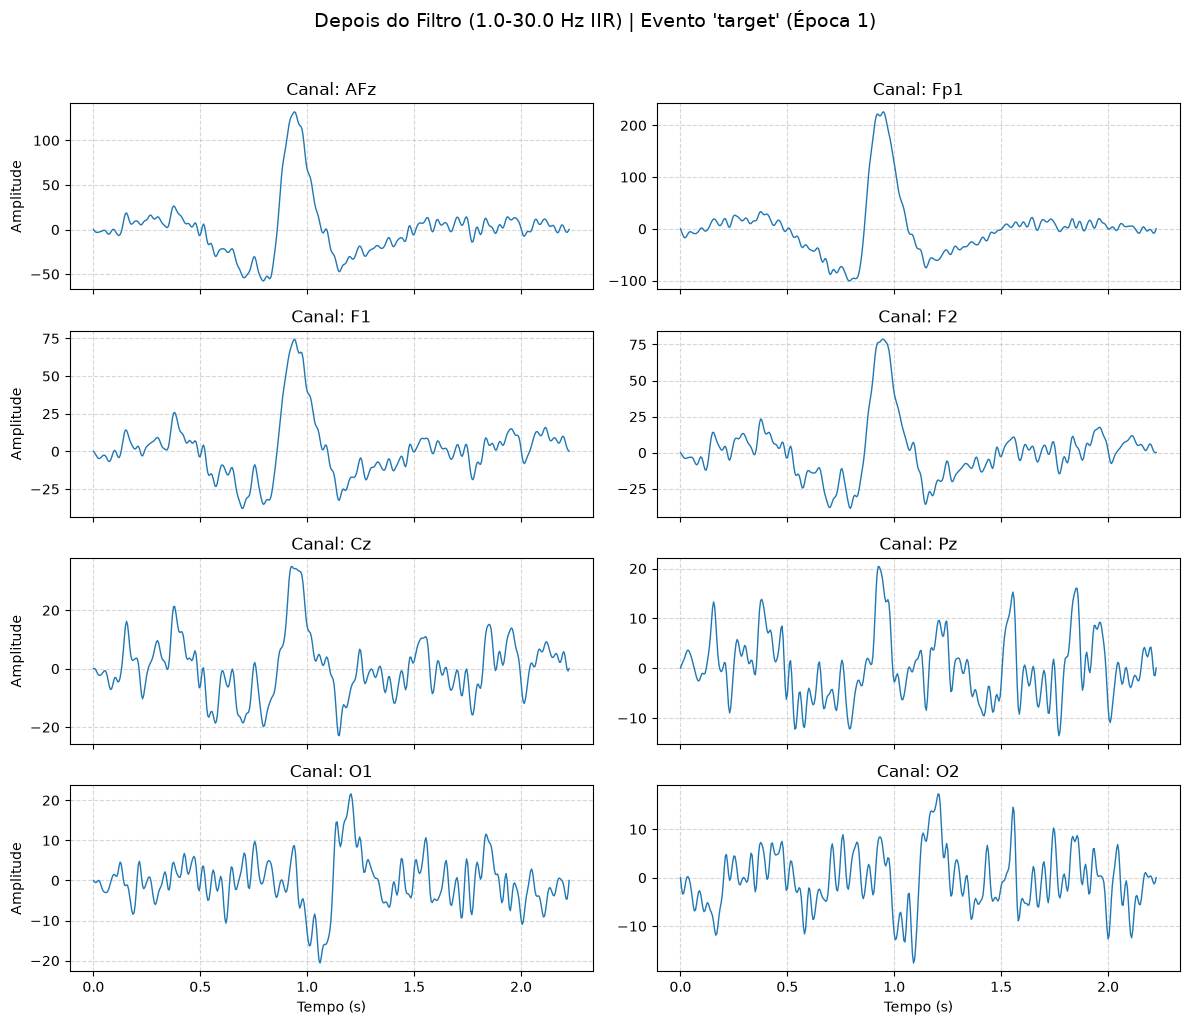

In [5]:
low_freq = 1.0
high_freq = 30.0

# Aplica o filtro passa-banda IIR Butterworth de fase zero
epochs_filtradas = epochs.copy().filter(l_freq=low_freq, h_freq=high_freq, method='iir')

# Plota a mesma época após o filtro
single_epoch_filtrada = epochs_filtradas[classe_alvo][indice_epoca]
plots_evoked(
    single_epoch_filtrada,
    canais=canais_selecionados,
    titulo=f"Depois do Filtro ({low_freq}-{high_freq} Hz IIR) | Evento '{classe_alvo}' (Época {indice_epoca})",
    color="#1f77b4"
)

    Using multitaper spectrum estimation with 7 DPSS windows
    Using multitaper spectrum estimation with 7 DPSS windows
Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
Plotting power spectral density (dB=True).
Averaging across epochs before plotting...


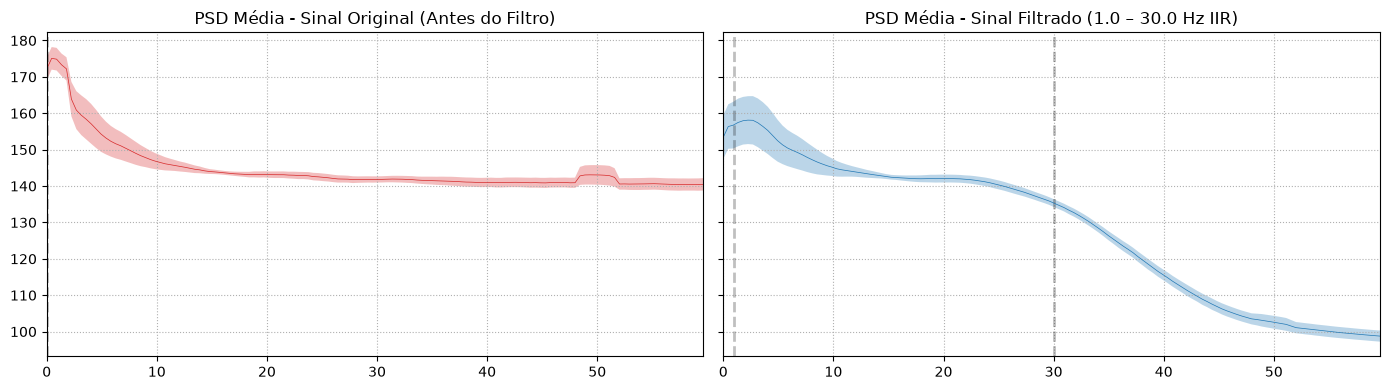

In [ ]:
# Verificação espectral antes e depois do filtro
psd_antes = epochs.compute_psd(fmax=60.0, picks='eeg')
psd_depois = epochs_filtradas.compute_psd(fmax=60.0, picks='eeg')

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)

psd_antes.plot(axes=axes[0], show=False, average=True, color="#d62728")
axes[0].set_title("PSD Média - Sinal Original (Antes do Filtro)")

psd_depois.plot(axes=axes[1], show=False, average=True, color="#1f77b4")
axes[1].set_title("PSD Média - Sinal Filtrado (1.0 – 30.0 Hz IIR)")

plt.tight_layout()
plt.show()

In [7]:
# Salva o objeto Epochs filtrado
epochs_filtradas.save('epochs_vp001_filtradas-epo.fif', overwrite=True)

[PosixPath('/home/pedrobornia/Documents/topicos-especiais/epochs_vp001_filtradas-epo.fif')]